# Studiu de caz comparativ: Ridge Regression și Lasso Regression

**Set de date:** Kaggle – *House Prices: Advanced Regression Techniques*  
**Variabila-țintă:** `SalePrice`  
**Modele comparate:** Linear Regression (referință), Ridge (L2) și Lasso (L1)

## Scop
Evaluarea influenței regularizării asupra erorii de predicție și a generalizării. Experimentul folosește aceeași partiționare train/test, aceeași preprocesare și validare încrucișată. Rezultatele sunt calculate din fișierul `train.csv`, care trebuie plasat în același director cu acest notebook.

**Reproductibilitate:** seed 42 pentru împărțirea inițială; validare K-Fold cu 5 fold-uri; versiunea bibliotecilor este afișată mai jos.


In [1]:
# 1. Importuri și configurare
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
DATA_PATH = "train.csv"
print("Python / biblioteci:")
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)


Python / biblioteci:
scikit-learn: 1.8.0
pandas: 2.2.3
NumPy: 2.3.5


## 2. Încărcarea și examinarea setului de date
Fișierul conține date de antrenare. `SalePrice` este ținta, iar `Id` este un identificator și nu este utilizat ca predictor.


In [2]:
df = pd.read_csv(DATA_PATH)
TARGET = "SalePrice"
if TARGET not in df.columns:
    raise ValueError(f"Coloana țintă {TARGET} nu există în {DATA_PATH}.")

print("Dimensiunea inițială:", df.shape)
print("Număr observații:", len(df))
print("Număr coloane:", len(df.columns))
print("Coloane cu valori lipsă:", int((df.isna().sum() > 0).sum()))
print("Total valori lipsă:", int(df.isna().sum().sum()))

display(df.head())
display(df[TARGET].describe().to_frame("SalePrice"))

X = df.drop(columns=[TARGET, "Id"], errors="ignore")
y = df[TARGET].astype(float)
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()
print(f"Predictori: {X.shape[1]} | Numerici: {len(num_cols)} | Categorici: {len(cat_cols)}")


Dimensiunea inițială: (1460, 81)
Număr observații: 1460
Număr coloane: 81
Coloane cu valori lipsă: 19
Total valori lipsă: 7829


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


Predictori: 79 | Numerici: 36 | Categorici: 43


## 3. Partiționare și preprocesare
Se utilizează 80% din observații pentru antrenare și 20% pentru testare. Imputarea și transformările sunt incluse în `Pipeline` și se ajustează numai pe datele de antrenare din fiecare fold, evitând scurgerea informației.

- Variabile numerice: imputare cu mediană și standardizare.
- Variabile categorice: imputare cu valoarea cea mai frecventă și One-Hot Encoding.
- One-Hot Encoding produce reprezentare densă pentru a permite antrenarea eficientă a Lasso pe acest set de dimensiuni moderate.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)


def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ], sparse_threshold=0)

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (1168, 79) | Test: (292, 79)


## 4. Antrenarea modelelor și selectarea hiperparametrilor
`Linear Regression` este reperul fără penalizare. Pentru Ridge și Lasso, `alpha` este selectat prin `GridSearchCV`, folosind 5 fold-uri și RMSE ca funcție de selecție. Testul rămâne neatins în timpul selecției.


In [4]:
selection_cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_configs = {
    "Linear Regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "Lasso": (Lasso(max_iter=30000, tol=1e-3, selection="cyclic"),
             {"model__alpha": [1, 10, 100, 500, 1000]})
}

fitted_models = {}
selection_summary = {}
for name, (estimator, param_grid) in model_configs.items():
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator)
    ])
    if param_grid:
        search = GridSearchCV(
            pipeline, param_grid=param_grid, cv=selection_cv,
            scoring="neg_root_mean_squared_error", n_jobs=1,
            return_train_score=True
        )
        search.fit(X_train, y_train)
        fitted_models[name] = search.best_estimator_
        selection_summary[name] = {
            "best_parameters": search.best_params_,
            "CV_RMSE": -search.best_score_
        }
    else:
        fitted_models[name] = pipeline.fit(X_train, y_train)
        selection_summary[name] = {"best_parameters": "N/A", "CV_RMSE": None}

print(json.dumps(selection_summary, indent=2))


{
  "Linear Regression": {
    "best_parameters": "N/A",
    "CV_RMSE": null
  },
  "Ridge": {
    "best_parameters": {
      "model__alpha": 10
    },
    "CV_RMSE": 31557.015504204574
  },
  "Lasso": {
    "best_parameters": {
      "model__alpha": 100
    },
    "CV_RMSE": 31603.95383207394
  }
}


## 5. Evaluarea pe seturile Train și Test
MAE, MSE și RMSE măsoară eroarea de predicție (valori mai mici sunt preferabile). R² măsoară variația explicată (valoare mai mare este preferabilă).


In [5]:
def evaluate(model, X_part, y_part):
    predictions = model.predict(X_part)
    mse = mean_squared_error(y_part, predictions)
    return {
        "MAE": mean_absolute_error(y_part, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_part, predictions)
    }

rows = []
for name, model in fitted_models.items():
    rows.append({"Model": name, "Set": "Train", **evaluate(model, X_train, y_train)})
    rows.append({"Model": name, "Set": "Test", **evaluate(model, X_test, y_test)})

results_df = pd.DataFrame(rows)
model_order = ["Linear Regression", "Ridge", "Lasso"]
display(results_df.round(3))


,Model,Set,MAE,MSE,RMSE,R2
0,Linear Regression,Train,12676.490,3.814253e+08,19530.112,0.936
1,Linear Regression,Test,18287.846,8.688066e+08,29475.525,0.887
2,Ridge,Train,14840.613,5.948154e+08,24388.837,0.900
3,Ridge,Test,19037.584,9.389445e+08,30642.201,0.878
4,Lasso,Train,14094.229,4.859793e+08,22044.939,0.919
5,Lasso,Test,17056.346,8.027794e+08,28333.361,0.895


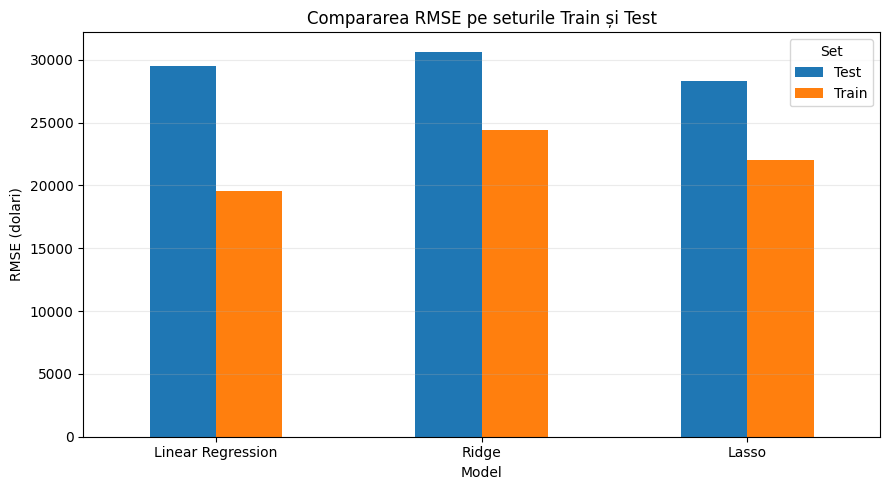

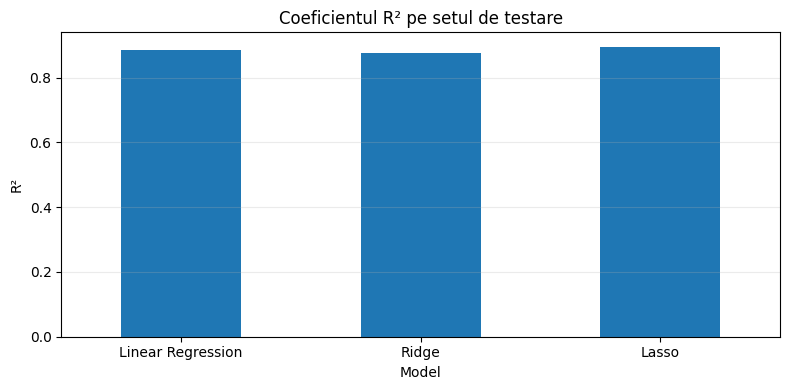

In [6]:
# Grafic 1: RMSE pe antrenare și testare
rmse_table = results_df.pivot(index="Model", columns="Set", values="RMSE").loc[model_order]
ax = rmse_table.plot(kind="bar", figsize=(9, 5))
ax.set_title("Compararea RMSE pe seturile Train și Test")
ax.set_ylabel("RMSE (dolari)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Grafic 2: R² pe setul de testare
r2_test = results_df[results_df["Set"] == "Test"].set_index("Model").loc[model_order, "R2"]
ax = r2_test.plot(kind="bar", figsize=(8, 4))
ax.set_title("Coeficientul R² pe setul de testare")
ax.set_ylabel("R²")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Stabilitatea modelelor: validare încrucișată imbricată
Pentru o estimare mai corectă a variației între fold-uri, folosim validare încrucișată imbricată pe setul de antrenare: 5 fold-uri externe pentru evaluare și 5 fold-uri interne pentru alegerea hiperparametrilor. Fiecare fold extern este evaluat pe observații care nu au participat nici la ajustarea modelului, nici la selecția lui `alpha` din acel fold.


In [7]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=123)
nested_rows = []
nested_alpha = {}

for name, (estimator, param_grid) in model_configs.items():
    fold_scores = []
    chosen_alphas = []
    for fold_no, (fit_idx, valid_idx) in enumerate(outer_cv.split(X_train), start=1):
        pipeline = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", estimator)
        ])
        if param_grid:
            inner_search = GridSearchCV(
                pipeline, param_grid=param_grid, cv=inner_cv,
                scoring="neg_root_mean_squared_error", n_jobs=1
            )
            inner_search.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            fold_model = inner_search.best_estimator_
            chosen_alphas.append(inner_search.best_params_["model__alpha"])
        else:
            fold_model = pipeline.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        fold_predictions = fold_model.predict(X_train.iloc[valid_idx])
        fold_rmse = np.sqrt(mean_squared_error(y_train.iloc[valid_idx], fold_predictions))
        fold_scores.append(fold_rmse)
        nested_rows.append({"Model": name, "Fold": fold_no, "RMSE": fold_rmse})
    nested_alpha[name] = chosen_alphas

nested_df = pd.DataFrame(nested_rows)
nested_summary = nested_df.groupby("Model")["RMSE"].agg(["mean", "std"]).reindex(model_order)
display(nested_summary.round(2))
print("Alpha selectat în fold-urile externe:", nested_alpha)


,mean,std
Model,,
Linear Regression,36397.20,8435.53
Ridge,31557.02,8066.49
Lasso,32072.56,8533.37


Alpha selectat în fold-urile externe: {'Linear Regression': [], 'Ridge': [10, 10, 10, 10, 10], 'Lasso': [500, 100, 500, 100, 100]}


## 7. Diferența Train–Test și coeficienții Lasso
Diferențele train–test sunt indicatori ai decalajului de generalizare, însă trebuie interpretate împreună cu nivelul absolut al erorii de test. Numărul coeficienților nuli arată cât de mult a simplificat Lasso reprezentarea după One-Hot Encoding.


In [8]:
gap_table = results_df.pivot(index="Model", columns="Set", values=["RMSE", "R2"]).loc[model_order]
gap_table["RMSE_gap_Test_minus_Train"] = gap_table[("RMSE", "Test")] - gap_table[("RMSE", "Train")]
gap_table["R2_gap_Train_minus_Test"] = gap_table[("R2", "Train")] - gap_table[("R2", "Test")]
display(gap_table.round(4))

lasso_estimator = fitted_models["Lasso"].named_steps["model"]
total_coefficients = lasso_estimator.coef_.size
nonzero_coefficients = int(np.count_nonzero(lasso_estimator.coef_))
zero_coefficients = int(total_coefficients - nonzero_coefficients)
print(f"Lasso: {nonzero_coefficients} coeficienți nenuli din {total_coefficients}.")
print(f"Coeficienți aduși la zero: {zero_coefficients} ({zero_coefficients / total_coefficients:.1%}).")


RMSE  ... R2_gap_Train_minus_Test
Set                      Test  ...                        
Model                          ...                        
Linear Regression  29475.5248  ...                  0.0493
Ridge              30642.2012  ...                  0.0227
Lasso              28333.3613  ...                  0.0232

[3 rows x 6 columns]

Lasso: 111 coeficienți nenuli din 285.
Coeficienți aduși la zero: 174 (61.1%).


## 8. Concluzii experimentale

Pe împărțirea train/test utilizată, Lasso obține cea mai mică eroare de test (RMSE ≈ 28.333 USD), cel mai mic MAE (≈ 17.056 USD) și cel mai mare R² de test (≈ 0,895). Lasso aduce la zero o parte importantă dintre coeficienții modelului, simplificând reprezentarea.

Ridge reduce decalajul train–test și obține cel mai bun RMSE mediu în validarea imbricată, însă pe testul final are o eroare mai mare decât Linear Regression și Lasso. Prin urmare, nu există o dominanță universală: rezultatul depinde de împărțirea datelor și de modul în care este evaluată performanța. Diferența dintre mediile Ridge și Lasso în validarea imbricată este mică în raport cu variația între fold-uri.

**Limitări:** o singură împărțire train/test; imputarea simplă poate pierde semnificația unor valori lipsă structurale; targetul `SalePrice` nu a fost transformat logaritmic și RMSE este sensibil la erori mari. Direcții viitoare: repetarea experimentului cu mai multe seed-uri, tratarea explicită a absenței unor facilități și transformarea logaritmică a țintei.
